# Speed units and stoppage signals (extras, clause d)

Settles the unit of the declared speed column (`speed_units.py`), profiles six per-frame signals around set-piece starts (`signal_profiles.py`), and asks whether long ball-missing gaps look like stoppages (`gap_stoppage.py`), which is clause d of the draft rule: *gap ≥ L and most players at walking pace or slower → dead*.

> **Run this notebook on the VM only.** Once run, its outputs are derived from the competition match. Before a copy with outputs leaves the VM, clear it:
> `jupyter nbconvert --clear-output --inplace eda_extras.ipynb`.

The script commands are **comments**: run them in a VM terminal from the team-repo root (or remove the `#` and prefix `!`). The cells below each command only read the summary CSVs the scripts wrote under `EDA_OUT` (default `~/eda_out`); none of them reads match data. Charts share one look from `plot_helpers.py`: one colour per set-piece `Type`, dark ink for observed values, a light grey band (p5–p95) with a dashed mean for the circular-shift null, and grey 'n < 5' stubs where there is too little to plot.

Definitions, defaults and CSV schemas: `eda/README.md`, section "Analyses".

In [1]:
import os
import sys
from pathlib import Path

# The eda/notebooks/ folder (Jupyter's working directory when the notebook is opened from there) and the
# script outputs. Override with EDA_DIR / EDA_OUT in the shell that starts Jupyter.
EDA_DIR = Path(os.environ.get("EDA_DIR", Path.cwd()))
EDA_OUT = Path(os.environ.get("EDA_OUT", Path.home() / "eda_out"))
sys.path.insert(0, str(EDA_DIR))

print("eda folder:", EDA_DIR, "(plot_helpers.py found)" if (EDA_DIR / "plot_helpers.py").is_file()
      else "(plot_helpers.py MISSING: set EDA_DIR)")
print("EDA_OUT   :", EDA_OUT)

eda folder: /home/robli-macbook-air-2026/more-than-a-hack/eda (plot_helpers.py found)
EDA_OUT   : /home/robli-macbook-air-2026/eda_out


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import plot_helpers as ph

ph.style()

In [3]:
su = ph.load_summary(EDA_OUT, "speed_units", "speed_units_summary.csv")
sp = ph.load_summary(EDA_OUT, "signal_profiles", "signal_profiles_summary.csv")
gs = ph.load_summary(EDA_OUT, "gap_stoppage", "gap_stoppage_summary.csv")
gs_walk = ph.load_summary(EDA_OUT, "gap_stoppage_walk15", "gap_stoppage_summary.csv")
K = ph.null_k(sp) if sp is not None else None
SIGNAL_LABEL = {"ball_missing": ("ball missing", "share of frames"),
                "ball_outside": ("ball outside the pitch", "share of frames"),
                "ball_still": ("ball still (run ≥ min)", "share of frames"),
                "slow_players": ("players below walking pace", "share of players"),
                "reproj_error": ("homography reprojection error", "px"),
                "n_tracked": ("tracked player slots", "slots")}

## 1. Is the declared speed column in km/h or m/s?

In [4]:
# cd ~/more-than-a-hack
# PYTHONPATH="$PWD" python3 eda/scripts/speed_units.py "$HOME/eda_out/speed_units"

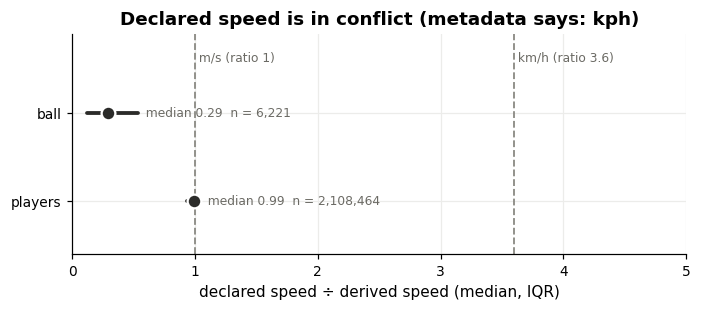

,players derived,players declared,ball derived,ball declared
percentile,,,,
p50,1.36,1.41,5.08,1.31
p99,6.58,6.44,24.60,5.92
p99.9,8.86,8.10,54.61,7.14


,players,ball
n_pairs,3253351.0,94065.0
n_over_cap,1605.0,216.0
n_ratio,2108464.0,6221.0


In [5]:
verdict = ph.get(su, "verdict", "overall", "", "verdict", text=True)
unit = ph.get(su, "meta", "all", "", "declared_speed_unit", text=True) or "not declared"
classes = ["players", "ball"]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
for ref, label in ((1.0, "m/s (ratio 1)"), (3.6, "km/h (ratio 3.6)")):
    ax.axvline(ref, color=ph.NULL_LINE, ls="--", lw=1.2)
    ax.text(ref, len(classes) - 0.45, " " + label, fontsize=8, color=ph.INK_2, va="bottom")
for i, c in enumerate(classes):
    med = ph.get(su, "ratio", c, "median", "declared_over_derived")
    lo = ph.get(su, "ratio", c, "p25", "declared_over_derived")
    hi = ph.get(su, "ratio", c, "p75", "declared_over_derived")
    n = ph.get(su, "ratio", c, "", "n_ratio")
    if n >= ph.MIN_N and np.isfinite(med):
        ax.plot([lo, hi], [i, i], color=ph.REAL, lw=2.5, solid_capstyle="round")
        ax.plot(med, i, "o", ms=9, color=ph.REAL, mec="white", mew=1.5)
        ax.text(hi, i, "  median {:.2f}  n = {:,}".format(med, int(n)), va="center", fontsize=8,
                color=ph.INK_2)
    else:
        ax.text(1.0, i, "  n < 5 (no declared speed?)", va="center", fontsize=8, color=ph.INK_2)
ax.set_yticks(range(len(classes)), classes)
ax.set_ylim(-0.6, len(classes) - 0.1)
ax.set_xlim(0, 5)
ax.set_xlabel("declared speed ÷ derived speed (median, IQR)")
ax.set_title("Declared speed is in {} (metadata says: {})".format(verdict, unit))
plt.show()

QS = ["p50", "p99", "p99.9"]
display(pd.DataFrame({"{} {}".format(c, kind): [ph.get(su, "speed", c, q, kind) for q in QS]
                      for c in classes for kind in ("derived", "declared")}, index=QS)
        .rename_axis("percentile").round(2))
display(pd.DataFrame({c: {m: ph.get(su, "ratio", c, "", m) for m in ("n_pairs", "n_over_cap", "n_ratio")}
                      for c in classes}))

BANDS = ["0-2", "2-5", "5-10", "10-20", "20+"]
if len(ph.pick(su, "ratio_by_speed")):
    print("ratio by derived-speed band (m/s): median [p25, p75], n")
    display(pd.DataFrame({c: ["{:.2f} [{:.2f}, {:.2f}]  n = {:,}".format(
        *(ph.get(su, "ratio_by_speed", c, b, m) for m in ("median", "p25", "p75")),
        int(ph.get(su, "ratio_by_speed", c, b, "n_ratio")))
        if ph.get(su, "ratio_by_speed", c, b, "n_ratio") >= ph.MIN_N else "n < 5"
        for b in BANDS] for c in classes}, index=BANDS).rename_axis("derived speed (m/s)"))
    print("declared ball speed on ball-visible graded frames")
    display(pd.DataFrame({"frames": {k: int(ph.get(su, "ball_declared", "ball", k, "n_frames"))
                                     for k in ("nan", "zero", "positive")}}))

,frames,share
declared ball speed,,
nan,NaN,NaN
zero,NaN,NaN
positive,NaN,NaN


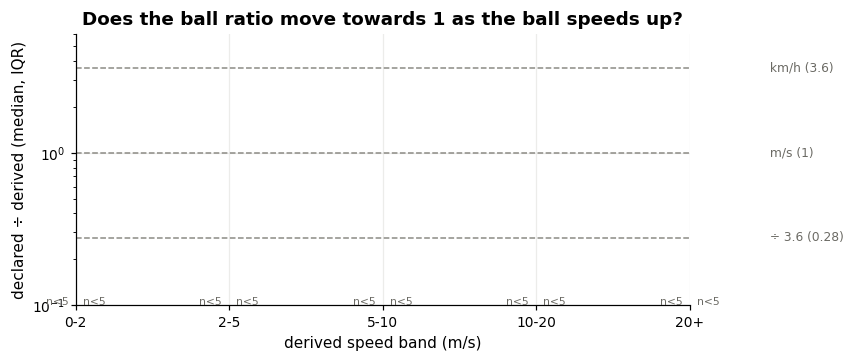

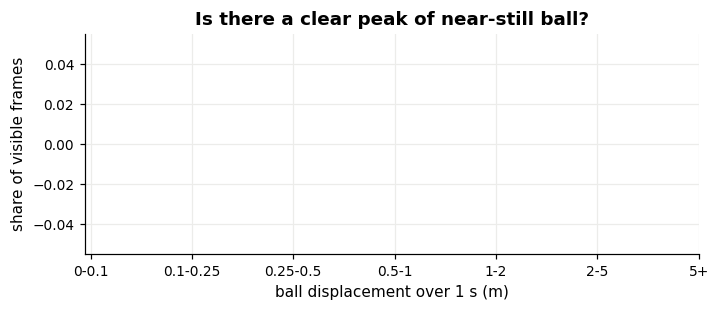

In [6]:
BANDS = ["0-2", "2-5", "5-10", "10-20", "20+"]
SERIES = (("players", ph.INK_2, -0.12), ("ball", ph.REAL, 0.12))

# (a) What declared ball speed looks like on visible-ball frames
decl = pd.Series({b: ph.get(su, "ball_declared", "ball", b, "n_frames")
                  for b in ("nan", "zero", "positive")})
display(pd.DataFrame({"frames": decl, "share": (decl / decl.sum()).round(3)})
        .rename_axis("declared ball speed"))

# (b) Ratio by derived-speed band: jitter, unit error, or noise?
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for ref, label in ((1.0, "m/s (1)"), (1 / 3.6, "÷ 3.6 (0.28)"), (3.6, "km/h (3.6)")):
    ax.axhline(ref, color=ph.NULL_LINE, ls="--", lw=1)
    ax.text(len(BANDS) - 0.5, ref, " " + label, fontsize=8, color=ph.INK_2, va="center")
for scope, colour, off in SERIES:
    labelled = False                  # label each series on its first drawn band
    for i, b in enumerate(BANDS):
        med, lo, hi, n = (ph.get(su, "ratio_by_speed", scope, b, m)
                          for m in ("median", "p25", "p75", "n_ratio"))
        if not (n >= ph.MIN_N and np.isfinite(med)):
            ax.text(i + off, 0.1, "n<5", fontsize=7, color=ph.INK_2, ha="center")
            continue
        ax.plot([i + off] * 2, [lo, hi], color=colour, lw=2.5, solid_capstyle="round")
        ax.plot(i + off, med, "o", ms=7, color=colour, mec="white", mew=1.2,
                label=None if labelled else scope)
        labelled = True
        ax.text(i + off, hi, "{:,}".format(int(n)), fontsize=6, color=ph.INK_2,
                ha="center", va="bottom")
ax.set_yscale("log")
ax.set_ylim(0.1, 6)
ax.set_xticks(range(len(BANDS)), BANDS)
ax.set_xlabel("derived speed band (m/s)")
ax.set_ylabel("declared ÷ derived (median, IQR)")
ax.set_title("Does the ball ratio move towards 1 as the ball speeds up?")
if ax.get_legend_handles_labels()[1]:
    ax.legend(fontsize=8, loc="upper left")
plt.show()

# (c) How far the ball moves in 1 s: is there a clear 'stationary' peak?
DISP = ["0-0.1", "0.1-0.25", "0.25-0.5", "0.5-1", "1-2", "2-5", "5+"]
share = [ph.get(su, "ball_disp", "ball", b, "share") for b in DISP]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.bar(range(len(DISP)), share, color=ph.REAL)
ax.set_xticks(range(len(DISP)), DISP)
ax.set_xlabel("ball displacement over 1 s (m)")
ax.set_ylabel("share of visible frames")
ax.set_title("Is there a clear peak of near-still ball?")
plt.show()

**How to read this.** Each row shows the median (dot) and interquartile range (bar) of declared speed divided by the speed derived from positions, on pairs below the plausibility cap. A median near 3.6 means the column is in km/h, near 1 m/s; the title gives the script's verdict. The tables give the speed percentiles (derived in m/s, declared in its own unit) and how many pairs were over the cap (slot swaps). A wide IQR means the declared speed is smoothed; later scripts use derived speed anyway. The last two tables split the ratio by derived-speed band (a ratio that drifts with speed means smoothing or a cap) and count how the declared ball speed looks on frames where the ball is visible (mostly NaN or zero means the ball column is unusable).

**Takeaway.** _to fill in after running_

## 2. How far does the tracked ball move in one second?

In [7]:
# (same run as section 1)

In [8]:
DISP = ["0-0.1", "0.1-0.25", "0.25-0.5", "0.5-1", "1-2", "2-5", "5+"]
if not len(ph.pick(su, "ball_disp")):
    print("no ball_disp rows: rerun speed_units.py with the current version")
else:
    window = ph.get(su, "params", "all", "", "disp_window")
    share = [ph.get(su, "ball_disp", "ball", b, "share") for b in DISP]
    n = [ph.get(su, "ball_disp", "ball", b, "n_frames") for b in DISP]
    fig, ax = plt.subplots(figsize=(7.2, 3.6))
    ph.bars_with_n(ax, DISP, share, n, fmt="{:.1%}")
    ax.set_xlabel("ball displacement over {:g} s (m, half-open bands)".format(window))
    ax.set_ylabel("share of {:g} s windows".format(window))
    ax.set_title("How far does the tracked ball move in {:g} s?".format(window))
    plt.show()
    total = sum(n)
    display(pd.DataFrame({"windows": [int(total)],
                          "share < 0.1 m": [share[0]],
                          "share < 0.25 m": [share[0] + share[1]]}).round(4))

no ball_disp rows: rerun speed_units.py with the current version


**How to read this.** Each bar is the share of windows (ball visible at both ends, same half) in which the ball moved that far; the label adds the number of windows, and bands with fewer than 5 are grey stubs. A placed or waiting ball sits in the first band or two. `ball_stationary.py` calls the ball still below 0.5 m/s over 0.2 s, i.e. about 0.1 m; if the first band holds a visible share of windows, clause c has room to work and the threshold can stay; if it is nearly empty, the tracker hardly ever reports a still ball and clause c will label very little, whatever the threshold.

**Takeaway.** _to fill in after running_

## 3. Which signals move before a set piece starts, beyond chance?

In [9]:
# cd ~/more-than-a-hack
# PYTHONPATH="$PWD" python3 eda/scripts/signal_profiles.py "$HOME/eda_out/signal_profiles" --ends

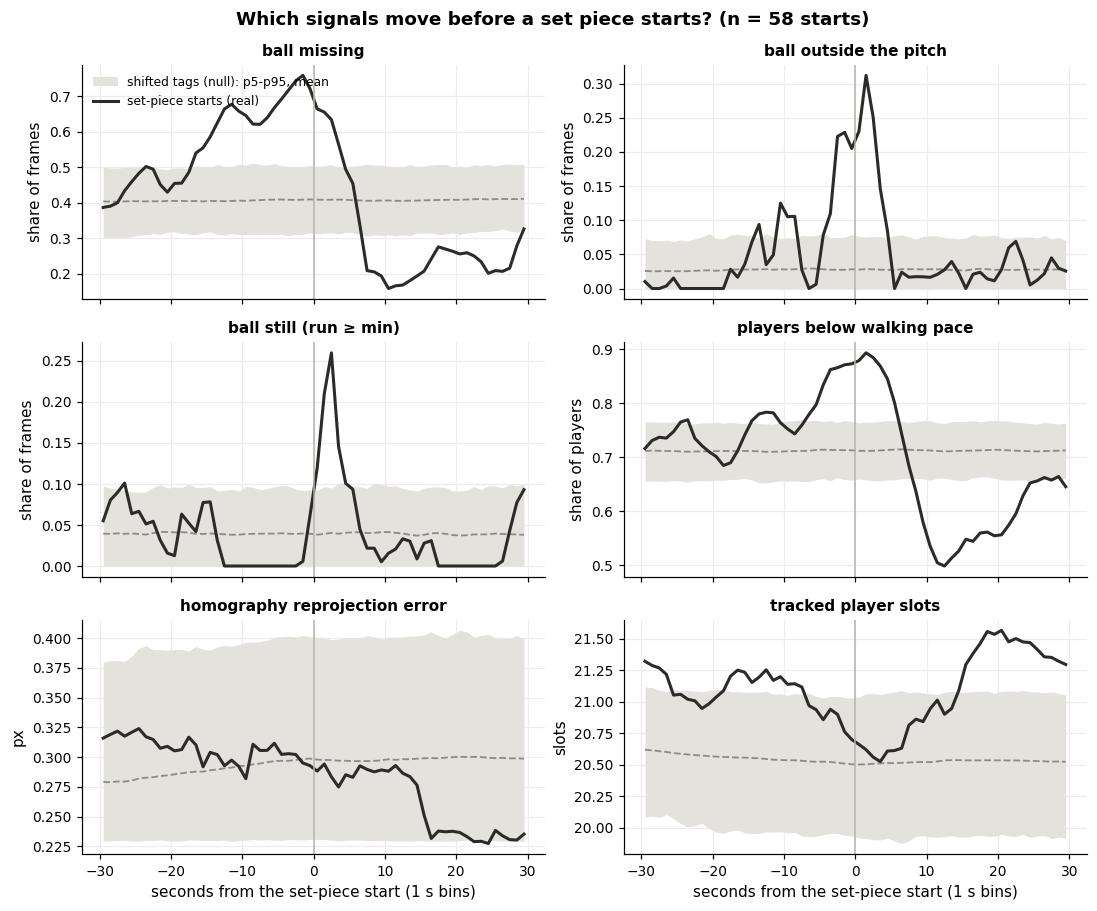

,baseline,10 s before: real,10 s before: null mean
signal,,,
ball missing,0.407,0.683,0.408
ball outside the pitch,0.027,0.109,0.028
ball still (run ≥ min),0.039,0.007,0.039
players below walking pace,0.712,0.814,0.713
homography reprojection error,0.296,0.301,0.296
tracked player slots,20.487,20.945,20.522


In [10]:
SP = "code:SET PIECES"


def profile(signal, group, anchor="start"):
    d = ph.pick(sp, "profile_" + anchor, "{}:{}".format(signal, group))
    d = d[d.bin != ""]
    out = d.pivot_table(index="bin", columns="metric", values="value", aggfunc="first")
    out.index = out.index.astype(float)
    return out.sort_index()


if not len(ph.pick(sp, "profile_start")):
    print("no profiles in this run (no Smart Tagging file): section skipped")
else:
    signals = [s for s in SIGNAL_LABEL if len(ph.pick(sp, "profile_start", "{}:{}".format(s, SP)))]
    shown, flat = [], []
    for s in signals:
        p = profile(s, SP)
        both = pd.concat([p["value"], p.get("null_mean", p["value"])])
        (flat if np.nanstd(both.values) < 1e-9 else shown).append(s)
    if flat:
        print("not drawn (constant, nothing to see):", ", ".join(flat))
    n_inst = int(ph.get(sp, "profile_start", "{}:{}".format(shown[0], SP), "", "n_instances"))
    cols = 2
    rows = int(np.ceil(len(shown) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.8 * rows), sharex=True, squeeze=False)
    for ax, s in zip(axes.flat, shown):
        p = profile(s, SP)
        x = p.index.values + 0.5          # bin centres
        if "null_p5" in p:
            ph.null_band(ax, x, p["null_p5"], p["null_p95"], p["null_mean"])
        ax.plot(x, p["value"], color=ph.REAL if n_inst >= ph.MIN_N else ph.SMALL_N, lw=2,
                label="set-piece starts (real)" if n_inst >= ph.MIN_N else "n < 5 starts")
        ax.axvline(0, color=ph.INK_3, lw=1)
        ax.set_title(SIGNAL_LABEL[s][0], fontsize=10)
        ax.set_ylabel(SIGNAL_LABEL[s][1])
    for ax in axes.flat[len(shown):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("seconds from the set-piece start (1 s bins)")
    axes.flat[0].legend(loc="upper left", fontsize=8)
    fig.suptitle("Which signals move before a set piece starts? (n = {:,} starts)".format(n_inst),
                 fontweight="bold")
    fig.tight_layout()
    plt.show()

    rows = []
    for s in shown:
        p = profile(s, SP)
        pre = p.loc[(p.index >= -10) & (p.index < 0)]
        base = ph.get(sp, "baseline", s, "", "mean")
        rows.append({"signal": SIGNAL_LABEL[s][0], "baseline": base,
                     "10 s before: real": pre["value"].mean(),
                     "10 s before: null mean": pre["null_mean"].mean() if "null_mean" in pre else np.nan})
    display(pd.DataFrame(rows).set_index("signal").round(3))

**How to read this.** One panel per signal (each has its own unit, so they cannot share an axis). The dark line is the pooled signal in 1 s bins around all set-piece starts; the grey band and dashed line are the same profile around circularly shifted starts. Signals that leave the band before 0 can mark the run-up (clause b) or the stoppage (clause d): rising *players below walking pace* supports clause d, a jump in *reprojection error* suggests camera cuts. Signals that stay inside the band are not worth a clause. Panels that would be constant are left out and named above the chart. The table compares the 10 s before the start with the null and the match-wide baseline.

**Takeaway.** _to fill in after running_

## 4. Do players slow down before every kind of restart?

In [11]:
# (same run as section 3)

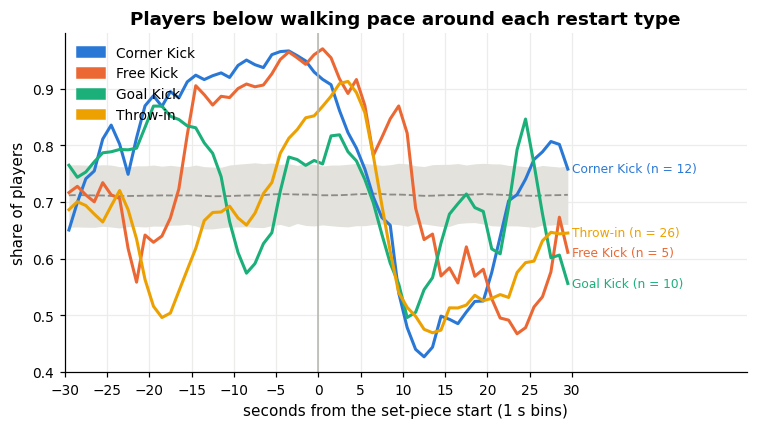

n < 5 starts, not drawn: Kick Off (After Goal), Kick Off (Start)


In [12]:
SIGNAL = "slow_players"     # change to any signal from section 2
if not len(ph.pick(sp, "profile_start")):
    print("no profiles in this run: section skipped")
else:
    groups = sorted({s.split(":", 1)[1] for s in ph.pick(sp, "profile_start").scope
                     if s.startswith(SIGNAL + ":type:")})
    groups = ph.sort_groups(groups)
    fig, ax = plt.subplots(figsize=(8, 4))
    ref = profile(SIGNAL, SP)
    if "null_p5" in ref:
        x = ref.index.values + 0.5
        ph.null_band(ax, x, ref["null_p5"], ref["null_p95"], ref["null_mean"],
                     label="all set pieces, shifted (null)")
    small = []
    for g in groups:
        p = profile(SIGNAL, g)
        n = int(ph.get(sp, "profile_start", "{}:{}".format(SIGNAL, g), "", "n_instances"))
        if n < ph.MIN_N:
            small.append(ph.group_label(g))
            continue
        x = p.index.values + 0.5
        ax.plot(x, p["value"], color=ph.type_colour(g), lw=2)
        last = p["value"].dropna()
        if len(last):
            ax.text(x[-1] + 0.5, last.iloc[-1], "{} (n = {})".format(ph.group_label(g), n),
                    color=ph.type_colour(g), fontsize=8, va="center")
    ax.axvline(0, color=ph.INK_3, lw=1)
    ax.set_xlim(ref.index.min(), ref.index.max() + 1 + 0.35 * (ref.index.max() - ref.index.min()))
    ax.set_xticks(np.arange(ref.index.min(), ref.index.max() + 1.01,
                            5 if ref.index.max() > 10 else 1))
    ax.set_xlabel("seconds from the set-piece start (1 s bins)")
    ax.set_ylabel(SIGNAL_LABEL[SIGNAL][1])
    ax.set_title("{} around each restart Type".format(SIGNAL_LABEL[SIGNAL][0]).capitalize())
    ph.type_legend(ax, [g for g in groups if ph.group_label(g) not in small], loc="upper left")
    plt.show()
    if small:
        print("n < 5 starts, not drawn:", ", ".join(small))

**How to read this.** One line per set-piece `Type` (fixed colours, labelled at the right end with its number of starts); the grey band is the null for all set pieces together, as a common reference. Types with fewer than 5 starts are not drawn and are listed below. If every Type rises above the band before its start, clause d can use one walking threshold for all restarts; if only some do (say corners and free kicks but not throw-ins), the quick restarts need clause a or b instead. Change `SIGNAL` to look at another signal.

**Takeaway.** _to fill in after running_

## 5. Do longer ball-missing gaps have more players walking?

In [13]:
# cd ~/more-than-a-hack
# PYTHONPATH="$PWD" python3 eda/scripts/gap_stoppage.py "$HOME/eda_out/gap_stoppage" --clusters 2
# PYTHONPATH="$PWD" python3 eda/scripts/gap_stoppage.py "$HOME/eda_out/gap_stoppage_walk15" --walk-ms 1.5 --clusters 2

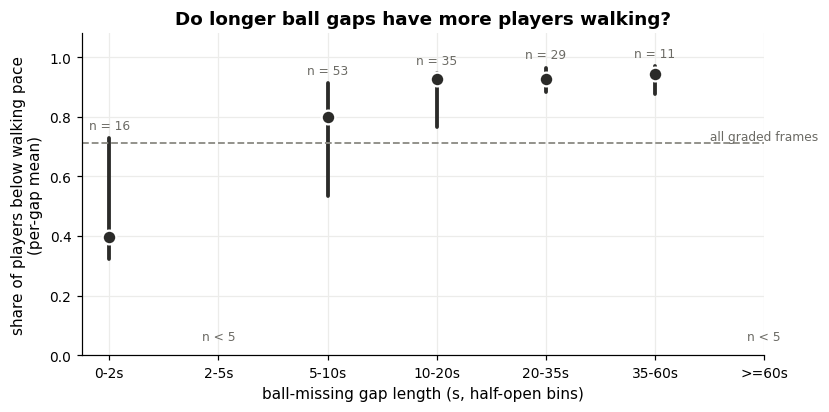

,gaps,length median (s),slow share median,reproj error median (px),tracked slots median,"slow share median, walk < 1.5 m/s"
gap length,,,,,,
0-2s,17.0,0.08,0.395,0.264,22.000,0.242
2-5s,1.0,4.88,0.952,0.163,18.934,0.863
5-10s,53.0,6.76,0.798,0.230,21.741,0.630
10-20s,35.0,12.20,0.927,0.236,21.495,0.757
20-35s,29.0,24.16,0.926,0.231,20.874,0.821
35-60s,11.0,45.64,0.944,0.215,19.497,0.843
>=60s,4.0,104.06,0.955,0.234,16.227,0.863
all,150.0,10.72,0.868,0.231,21.366,0.711


In [14]:
BINS = ["0-2s", "2-5s", "5-10s", "10-20s", "20-35s", "35-60s", ">=60s"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, b in enumerate(BINS):
    n = ph.get(gs, "gap_bin", "slow_players", b, "n")
    med, lo, hi = (ph.get(gs, "gap_bin", "slow_players", b, q) for q in ("median", "p25", "p75"))
    if n >= ph.MIN_N:
        ax.plot([i, i], [lo, hi], color=ph.REAL, lw=2.5, solid_capstyle="round")
        ax.plot(i, med, "o", ms=9, color=ph.REAL, mec="white", mew=1.5, zorder=3)
        ax.text(i, hi + 0.02, "n = {:,}".format(int(n)), ha="center", va="bottom", fontsize=8,
                color=ph.INK_2)
    else:
        ax.text(i, 0.05, "n < 5", ha="center", fontsize=8, color=ph.INK_2)
base = ph.get(sp, "baseline", "slow_players", "", "mean") if sp is not None else np.nan
if np.isfinite(base):
    ax.axhline(base, color=ph.NULL_LINE, ls="--", lw=1.2)
    ax.text(len(BINS) - 0.5, base, " all graded frames", fontsize=8, color=ph.INK_2, va="bottom",
            ha="right")
ax.set_xticks(range(len(BINS)), BINS)
ax.set_ylim(0, 1.08)
ax.set_xlabel("ball-missing gap length (s, half-open bins)")
ax.set_ylabel("share of players below walking pace\n(per-gap mean)")
ax.set_title("Do longer ball gaps have more players walking?")
plt.show()

table = {}
for b in BINS + ["all"]:
    row = {"gaps": ph.get(gs, "gap_bin", "all", b, "n_gaps"),
           "length median (s)": ph.get(gs, "gap_bin", "length", b, "median"),
           "slow share median": ph.get(gs, "gap_bin", "slow_players", b, "median"),
           "reproj error median (px)": ph.get(gs, "gap_bin", "reproj_error", b, "median"),
           "tracked slots median": ph.get(gs, "gap_bin", "n_tracked", b, "median")}
    if gs_walk is not None:
        row["slow share median, walk < 1.5 m/s"] = ph.get(gs_walk, "gap_bin", "slow_players", b, "median")
    table[b] = row
display(pd.DataFrame(table).T.rename_axis("gap length").round(3))

**How to read this.** For each gap-length bin, the dot is the median over gaps of the per-gap mean share of players below walking pace, and the bar its interquartile range; bins with fewer than 5 gaps say "n < 5". The dashed line is the share over all graded frames. A climb with gap length, ending well above the baseline, supports clause d; the first bin whose median is above about 0.8 suggests L. A wide IQR in the long bins means some long gaps are live play the tracker lost, which clause d must not call dead. The table adds reprojection error, tracked slots and the stricter walking threshold.

**Takeaway.** _to fill in after running_

## 6. Do gaps fall into stoppage-like and live-like groups?

In [15]:
# (same run as section 5, with --clusters 2)

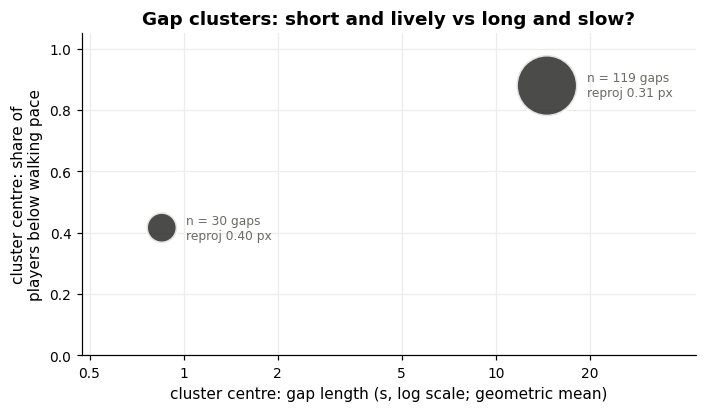

,gaps,length (s),slow share,reproj error (px)
cluster 1,30.0,0.852,0.416,0.400
cluster 2,119.0,14.582,0.880,0.307


In [16]:
cl = ph.pick(gs, "cluster")
if not len(cl):
    print("no clusters in this run (run with --clusters 2 and a homography file)")
else:
    names = sorted(s for s in cl.scope.unique() if s.startswith("cluster "))
    size = [ph.get(gs, "cluster", s, "", "size") for s in names]
    length = [ph.get(gs, "cluster", s, "", "length") for s in names]
    slow = [ph.get(gs, "cluster", s, "", "slow_players") for s in names]
    rep = [ph.get(gs, "cluster", s, "", "reproj_error") for s in names]
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    area = 1600 * np.array(size) / max(size)
    ax.scatter(length, slow, s=area, color=ph.REAL, alpha=0.85, edgecolor="white", linewidth=2)
    for L, s_, n, r, a in zip(length, slow, size, rep, area):
        ax.annotate("n = {:,} gaps\nreproj {:.2f} px".format(int(n), r), (L, s_),
                    textcoords="offset points", xytext=(np.sqrt(a) / 2 + 6, 0), va="center",
                    fontsize=8, color=ph.INK_2)
    ax.set_xscale("log")
    ax.set_xlim(min(length) / 1.8, max(length) * 3)
    ticks = [t for t in (0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200)
             if min(length) / 1.8 <= t <= max(length) * 3]
    ax.set_xticks(ticks, ["{:g}".format(t) for t in ticks])
    ax.minorticks_off()
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("cluster centre: gap length (s, log scale; geometric mean)")
    ax.set_ylabel("cluster centre: share of\nplayers below walking pace")
    ax.set_title("Gap clusters: short and lively vs long and slow?")
    plt.show()
    display(pd.DataFrame({"gaps": size, "length (s)": length, "slow share": slow,
                          "reproj error (px)": rep}, index=names).round(3))

**How to read this.** Each bubble is a k-means cluster of gaps (standardised log length, slow-player share and reprojection error), placed at its centre; bubble area is the number of gaps, the label adds the reprojection error. Two well-separated bubbles (short with few walkers, long with most players walking and a higher error) support one threshold rule for clause d; overlapping centres mean length alone does not separate stoppages from lost live play.

**Takeaway.** _to fill in after running_